Generation 50: Best Cost = $18348.8798/h
Generation 100: Best Cost = $18242.1113/h
Generation 150: Best Cost = $18161.6320/h
Generation 200: Best Cost = $18156.2065/h
Generation 250: Best Cost = $18156.2065/h
Generation 300: Best Cost = $18156.0575/h
Generation 350: Best Cost = $18155.9219/h
Generation 400: Best Cost = $18155.9219/h
Generation 450: Best Cost = $18155.8730/h
Generation 500: Best Cost = $18155.5150/h

========== GENETIC ALGORITHM RESULTS ==========
Total Demand: 1800.0 MW
Total Generated Power: 1800.0 MW
Power Balance Error: -0.0 MW
Initial Feasible Cost: 19270.0271 $/h
Optimized Fuel Cost: 18155.515 $/h
Cost Savings: 1114.5121 $/h
Cost Reduction: 5.7837 %

========== OPTIMAL GENERATOR DISPATCH ==========


,Generator,Minimum Power (MW),Maximum Power (MW),Optimal Power (MW),Fuel Cost ($/h)
0,G1,0.0,680.0,269.7651,2760.5729
1,G2,0.0,360.0,151.1743,1559.5266
2,G3,0.0,360.0,224.8047,2159.6223
3,G4,60.0,180.0,110.7955,1146.1044
4,G5,60.0,180.0,110.4597,1140.0937
5,G6,60.0,180.0,160.0214,1564.2553
6,G7,60.0,180.0,159.7452,1559.2227
7,G8,60.0,180.0,160.0812,1565.3468
8,G9,60.0,180.0,109.9296,1130.6054
9,G10,40.0,120.0,78.1440,821.6267


Total Generation: 1800.0 MW
Total Fuel Cost: 18155.515 $/h


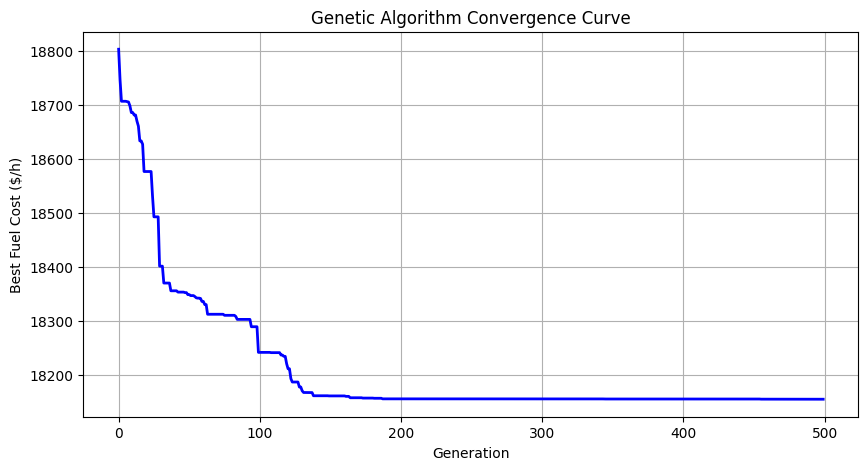

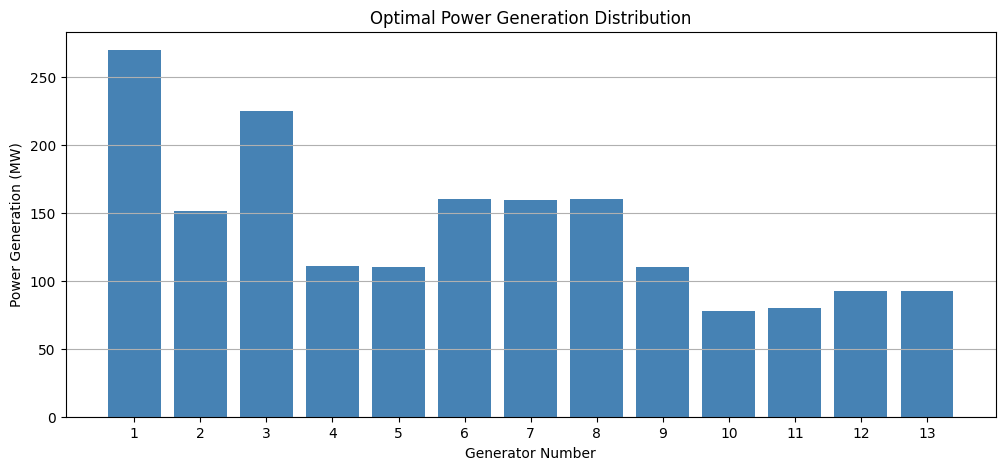

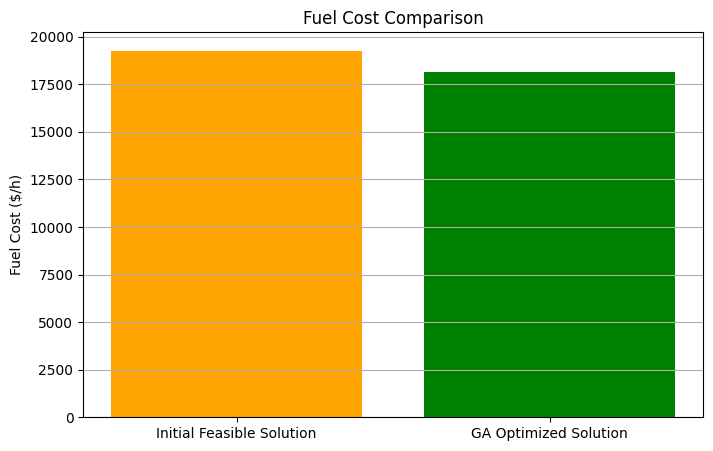

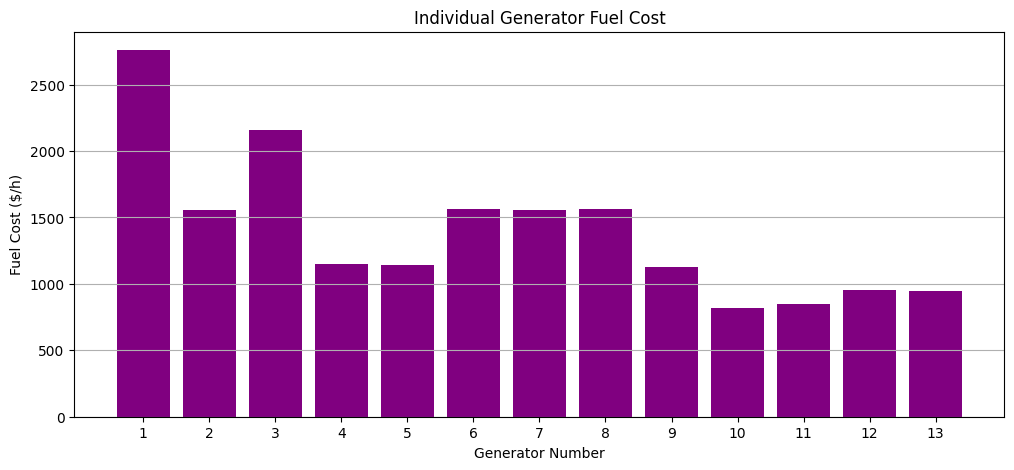


Genetic Algorithm Economic Load Dispatch Completed!


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
rng = np.random.default_rng(42)

N = 13
demand = 1800.0

Pmin = np.array([
    0, 0, 0, 60, 60, 60, 60,
    60, 60, 40, 40, 55, 55
], dtype=float)

Pmax = np.array([
    680, 360, 360, 180, 180, 180, 180,
    180, 180, 120, 120, 120, 120
], dtype=float)

a = np.array([
    0.00028, 0.00056, 0.00056,
    0.00324, 0.00324, 0.00324,
    0.00324, 0.00324, 0.00324,
    0.00284, 0.00284, 0.00284, 0.00284
])

b = np.array([
    8.1, 8.1, 8.1,
    7.74, 7.74, 7.74, 7.74, 7.74, 7.74,
    8.6, 8.6, 8.6, 8.6
])

c = np.array([
    550, 309, 307,
    240, 240, 240, 240, 240, 240,
    126, 126, 126, 126
])

e = np.array([
    300, 200, 200,
    150, 150, 150, 150, 150, 150,
    100, 100, 100, 100
])

f = np.array([
    0.035, 0.042, 0.042,
    0.063, 0.063, 0.063, 0.063, 0.063, 0.063,
    0.084, 0.084, 0.084, 0.084
])

population_size = 100
generations = 500
crossover_rate = 0.90
mutation_rate = 0.10
elite_size = 2
tournament_size = 3


def repair(solution):

    solution = np.clip(
        solution.copy(),
        Pmin,
        Pmax
    )

    for _ in range(100):

        difference = demand - np.sum(solution)

        if abs(difference) < 1e-8:
            break

        if difference > 0:

            capacity = Pmax - solution
            available = np.sum(capacity)

            if available < 1e-10:
                break

            adjustment = min(difference, available)

            solution += adjustment * capacity / available

        else:

            capacity = solution - Pmin
            available = np.sum(capacity)

            if available < 1e-10:
                break

            adjustment = min(-difference, available)

            solution -= adjustment * capacity / available

    return np.clip(solution, Pmin, Pmax)


def fuel_cost(solution):

    cost = (
        a * solution**2
        + b * solution
        + c
        + np.abs(
            e * np.sin(f * (Pmin - solution))
        )
    )

    return np.sum(cost)


def initialize_population():

    population = []

    for _ in range(population_size):

        individual = rng.uniform(Pmin, Pmax)

        individual = repair(individual)

        population.append(individual)

    return np.array(population)


def evaluate_population(population):

    return np.array([
        fuel_cost(individual)
        for individual in population
    ])


def selection(population, fitness):

    indices = rng.choice(
        len(population),
        size=tournament_size,
        replace=False
    )

    best_index = indices[np.argmin(fitness[indices])]

    return population[best_index].copy()


def crossover(parent1, parent2):

    if rng.random() < crossover_rate:

        alpha = rng.random(N)

        child1 = (
            alpha * parent1
            + (1 - alpha) * parent2
        )

        child2 = (
            alpha * parent2
            + (1 - alpha) * parent1
        )

    else:

        child1 = parent1.copy()
        child2 = parent2.copy()

    return repair(child1), repair(child2)


def mutation(solution):

    mutated = solution.copy()

    mask = rng.random(N) < mutation_rate

    mutation_strength = 0.08 * (Pmax - Pmin)

    changes = rng.normal(
        0,
        mutation_strength,
        N
    )

    mutated[mask] += changes[mask]

    return repair(mutated)


def genetic_algorithm():

    population = initialize_population()

    fitness = evaluate_population(population)

    best_index = np.argmin(fitness)

    best_solution = population[best_index].copy()

    best_fitness = fitness[best_index]

    convergence = []

    for generation in range(generations):

        sorted_indices = np.argsort(fitness)

        new_population = [
            population[i].copy()
            for i in sorted_indices[:elite_size]
        ]

        while len(new_population) < population_size:

            parent1 = selection(population, fitness)

            parent2 = selection(population, fitness)

            child1, child2 = crossover(
                parent1,
                parent2
            )

            child1 = mutation(child1)

            child2 = mutation(child2)

            new_population.append(child1)

            if len(new_population) < population_size:
                new_population.append(child2)

        population = np.array(new_population)

        fitness = evaluate_population(population)

        current_best_index = np.argmin(fitness)

        if fitness[current_best_index] < best_fitness:

            best_fitness = fitness[current_best_index]

            best_solution = population[
                current_best_index
            ].copy()

        convergence.append(best_fitness)

        if (generation + 1) % 50 == 0:

            print(
                f"Generation {generation + 1}: "
                f"Best Cost = ${best_fitness:.4f}/h"
            )

    return best_solution, best_fitness, convergence


best_solution, best_cost, convergence = genetic_algorithm()

best_solution = repair(best_solution)

generation_costs = (
    a * best_solution**2
    + b * best_solution
    + c
    + np.abs(
        e * np.sin(f * (Pmin - best_solution))
    )
)

total_generation = np.sum(best_solution)

power_balance = total_generation - demand

baseline_solution = repair((Pmin + Pmax) / 2)

baseline_cost = fuel_cost(baseline_solution)

cost_savings = baseline_cost - best_cost

savings_percentage = (
    cost_savings / baseline_cost
) * 100

print("\n========== GENETIC ALGORITHM RESULTS ==========")

print("Total Demand:", demand, "MW")

print("Total Generated Power:",
      round(total_generation, 6), "MW")

print("Power Balance Error:",
      round(power_balance, 8), "MW")

print("Initial Feasible Cost:",
      round(baseline_cost, 4), "$/h")

print("Optimized Fuel Cost:",
      round(best_cost, 4), "$/h")

print("Cost Savings:",
      round(cost_savings, 4), "$/h")

print("Cost Reduction:",
      round(savings_percentage, 4), "%")

print("\n========== OPTIMAL GENERATOR DISPATCH ==========")

results = pd.DataFrame({
    "Generator": [f"G{i+1}" for i in range(N)],
    "Minimum Power (MW)": Pmin,
    "Maximum Power (MW)": Pmax,
    "Optimal Power (MW)": best_solution,
    "Fuel Cost ($/h)": generation_costs
})

display(results.round(4))

print("Total Generation:", round(total_generation, 4), "MW")
print("Total Fuel Cost:", round(best_cost, 4), "$/h")

plt.figure(figsize=(10, 5))

plt.plot(
    convergence,
    color="blue",
    linewidth=2
)

plt.title("Genetic Algorithm Convergence Curve")

plt.xlabel("Generation")

plt.ylabel("Best Fuel Cost ($/h)")

plt.grid(True)

plt.show()


plt.figure(figsize=(12, 5))

plt.bar(
    np.arange(1, N + 1),
    best_solution,
    color="steelblue"
)

plt.xlabel("Generator Number")

plt.ylabel("Power Generation (MW)")

plt.title("Optimal Power Generation Distribution")

plt.xticks(np.arange(1, N + 1))

plt.grid(axis="y")

plt.show()


plt.figure(figsize=(8, 5))

plt.bar(
    ["Initial Feasible Solution", "GA Optimized Solution"],
    [baseline_cost, best_cost],
    color=["orange", "green"]
)

plt.ylabel("Fuel Cost ($/h)")

plt.title("Fuel Cost Comparison")

plt.grid(axis="y")

plt.show()


plt.figure(figsize=(12, 5))

plt.bar(
    np.arange(1, N + 1),
    generation_costs,
    color="purple"
)

plt.xlabel("Generator Number")

plt.ylabel("Fuel Cost ($/h)")

plt.title("Individual Generator Fuel Cost")

plt.xticks(np.arange(1, N + 1))

plt.grid(axis="y")

plt.show()


print("\nGenetic Algorithm Economic Load Dispatch Completed!")
